# Did Removing the Dust Fix It?

**Comparing "[Fe/H] only" with "[Fe/H] + E(B−V)" before and after correcting the HUGS ridgelines for interstellar dust**

> **The short version.** Before the correction, a model that knew only a cluster's metallicity predicted its red-giant ridgeline badly, and adding the dust amount (E(B−V)) cut the error by more than half. After we subtract the dust effect using a standard extinction law, metallicity alone does the whole job, and adding E(B−V) no longer helps. That is exactly what we expect if the HUGS ridgelines were uncorrected for dust and our correction is right. (The collapsed code cells do the fitting. Every number below is computed from them.)

### The idea in plain words
Dust between us and a star makes it look **redder and fainter**, and it does so more for blue/ultraviolet light than for red light. The Hubble ridgelines we were given were measured *as observed*, so a dusty cluster's red-giant track is shifted compared with a clean one, regardless of its metallicity.

We removed that shift using the standard Milky Way extinction law (Fitzpatrick 1999, R_V = 3.1), applied to a red-giant spectrum through each Hubble filter, for each cluster's catalogued E(B−V):

* corrected colour = observed colour − (extinction in the first filter − extinction in the second)
* corrected magnitude = observed magnitude − extinction in that filter

The result is a new dataset, `data/GC Ridgelines dereddened.zip`, with the same layout as the original. The script that makes it is `scripts/deredden_ridgelines.py`.

**How we test it.** We use the same "forward model" as before, which predicts a cluster's ridgeline from its properties, and score it on clusters it has never seen. If the correction works, [Fe/H] should explain the ridges by itself, and E(B−V) should have nothing left to add.

In [1]:
import os, re, io, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVR
from sklearn.model_selection import LeaveOneOut, GridSearchCV, cross_val_predict

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 11})

PROJECT_DIR = Path().resolve()
while PROJECT_DIR.name != 'spectroscopy-regression' and PROJECT_DIR != PROJECT_DIR.parent:
    PROJECT_DIR = PROJECT_DIR.parent
os.chdir(PROJECT_DIR)

MLAB = r'$M_{\mathrm{F814W}}$ [mag]'
nice = lambda c: c.replace('-', '\u2212')
MINUS = '\u2212'

In [2]:
labels = pd.read_csv('data/GC_metallicity_harris.csv').set_index('NGC')['Fe/H_harris']
ebv_all = pd.read_csv('data/GC_reddening_harris.csv').set_index('NGC')['EBV']
Atab = pd.read_csv('data/GC_extinction_per_cluster.csv').set_index('NGC')      # E(B-V) and A_X per cluster

def load_ridges(zip_path):
    out = {}
    with zipfile.ZipFile(zip_path) as zf:
        for name in zf.namelist():
            m = re.search(r'NGC(\d+)_F814W_ridge\.csv$', name)
            if not m:
                continue
            d = pd.read_csv(io.BytesIO(zf.read(name)))
            d = d[d['low_conf'].astype(str) == 'False'].drop(columns='low_conf').dropna()
            if len(d) >= 2:
                out[int(m.group(1))] = d.sort_values('F814W_abs')
    return out

raw = load_ridges('data/GC Ridgelines.zip')
dd = load_ridges('data/GC Ridgelines dereddened.zip')
dd_g23 = load_ridges('data/GC Ridgelines dereddened_G23.zip')
COLORS = [c for c in next(iter(raw.values())).columns if '-' in c]

# Common grid of absolute magnitude covered by every cluster *after* dereddening (the more restrictive frame).
lo = max(d.F814W_abs.min() for d in dd.values()); hi = min(d.F814W_abs.max() for d in dd.values())
GRID = np.arange(np.ceil(lo * 4) / 4, np.floor(hi * 4) / 4 + 1e-9, 0.25)
limit_lo, limit_hi = max(dd, key=lambda n: dd[n].F814W_abs.min()), min(dd, key=lambda n: dd[n].F814W_abs.max())

def ridge_vectors(ridges, grid):
    rows = {}
    for n, d in ridges.items():
        x = d.F814W_abs.to_numpy()
        if grid.min() < x.min() or grid.max() > x.max():
            continue
        rows[n] = np.concatenate([np.interp(grid, x, d[c].to_numpy()) for c in COLORS])
    return pd.DataFrame(rows).T

V_raw, V_dd, V_g23 = (ridge_vectors(r, GRID) for r in (raw, dd, dd_g23))
common = sorted(set(V_raw.index) & set(V_dd.index) & set(V_g23.index))
Yraw, Ydd, Yg23 = (V.loc[common].to_numpy() for V in (V_raw, V_dd, V_g23))
fv, ev = labels.loc[common].to_numpy(), ebv_all.loc[common].to_numpy()
ncol, nbin = len(COLORS), len(GRID)

In [3]:
class ForwardModel:
    """PCA(k) on the ridge vectors + polynomial regression from inputs to PCA scores."""
    def __init__(self, k=3, deg=2):
        self.k, self.deg = k, deg
    def fit(self, X, Y):
        self.scaler = StandardScaler().fit(X)
        self.pca = PCA(n_components=self.k).fit(Y)
        self.reg = make_pipeline(PolynomialFeatures(self.deg), LinearRegression()).fit(self.scaler.transform(X), self.pca.transform(Y))
        return self
    def predict(self, X):
        return self.pca.inverse_transform(self.reg.predict(self.scaler.transform(X)))

def loo_forward(X, Y, k, deg):
    P = np.zeros_like(Y, dtype=float); idx = np.arange(len(Y))
    for i in idx:
        tr = idx != i
        P[i] = ForwardModel(k, deg).fit(X[tr], Y[tr]).predict(X[[i]])[0]
    return P

rmse = lambda P, T: float(np.sqrt(np.mean((P - T) ** 2)))
loo_mean = lambda T: np.array([T[np.arange(len(T)) != i].mean(0) for i in range(len(T))])
INPUTS = {'[Fe/H] only': np.c_[fv], 'E(B' + MINUS + 'V) only': np.c_[ev], '[Fe/H] + E(B' + MINUS + 'V)': np.c_[fv, ev]}
DATASETS = {'Raw (as observed)': Yraw, 'Dust-corrected': Ydd}
FIXED = (3, 2)                      # a single untuned setting (k=3 PCA components, quadratic)

# ---- main comparison: best of a small grid, and one fixed untuned setting
scen = {}
for dname, Y in DATASETS.items():
    for iname, X in INPUTS.items():
        best = None
        for k in [2, 3, 4]:
            for deg in [1, 2, 3]:
                P = loo_forward(X, Y, k, deg)
                r = rmse(P, Y)
                if (k, deg) == FIXED: fixed_r, fixed_P = r, P
                if best is None or r < best['rmse']: best = dict(rmse=r, k=k, deg=deg, P=P)
        scen[(dname, iname)] = dict(best=best, fixed_rmse=fixed_r, fixed_P=fixed_P)
base_rmse = {d: rmse(loo_mean(Y), Y) for d, Y in DATASETS.items()}

# ---- remaining dust signal in each colour (linear fit of colour on [Fe/H] and E(B-V) at M = 0)
i0 = int(np.argmin(np.abs(GRID)))
def dust_slopes(Y):
    A = np.c_[np.ones(len(Y)), fv, ev]
    out = []
    for ci in range(ncol):
        y = Y[:, ci * nbin + i0]
        beta = np.linalg.lstsq(A, y, rcond=None)[0]
        r = y - A @ beta
        se = np.sqrt(np.diag(np.linalg.inv(A.T @ A)) * r.var(ddof=3))
        out.append((beta[2], se[2], beta[1], se[1]))
    return np.array(out)
slopes = {d: dust_slopes(Y) for d, Y in DATASETS.items()}
Ac = Atab.loc[common]
law_slope = np.array([np.median(((Ac['A_' + c.split('-')[0]] - Ac['A_' + c.split('-')[1]]) / Ac['EBV'])[Ac['EBV'] > 0.05]) for c in COLORS])

# ---- how strong should the correction be? scale the extinction by s and watch the [Fe/H]-only error
SWEEP_GRID = np.array([-0.75, -0.5, -0.25])
S_VALUES = np.round(np.arange(0, 1.51, 0.125), 3)
def deredden(d, n, s):
    d = d.copy()
    for c in COLORS:
        x, y = c.split('-')
        d[c] = d[c] - s * (Atab.loc[n, 'A_' + x] - Atab.loc[n, 'A_' + y])
    d['F814W_abs'] = d['F814W_abs'] - s * Atab.loc[n, 'A_F814W']
    return d
sweep = {k: [] for k in ['[Fe/H] only', '[Fe/H] + E(B' + MINUS + 'V)']}
for s in S_VALUES:
    Vs = ridge_vectors({n: deredden(d, n, s) for n, d in raw.items()}, SWEEP_GRID)
    assert set(common) <= set(Vs.index), f'grid not covered for s={s}'
    Ys_ = Vs.loc[common].to_numpy()
    sweep['[Fe/H] only'].append(rmse(loo_forward(np.c_[fv], Ys_, *FIXED), Ys_))
    sweep['[Fe/H] + E(B' + MINUS + 'V)'].append(rmse(loo_forward(np.c_[fv, ev], Ys_, *FIXED), Ys_))
# sanity: our in-notebook correction at s = 1 reproduces the saved dataset
chk = ridge_vectors({n: deredden(d, n, 1.0) for n, d in raw.items()}, SWEEP_GRID).loc[common].to_numpy()
chk_ref = ridge_vectors(dd, SWEEP_GRID).loc[common].to_numpy()
assert np.abs(chk - chk_ref).max() < 2e-3, 'in-notebook correction differs from saved dataset'

# ---- robustness: a different extinction law (Gordon et al. 2023)
g23_r = {iname: rmse(loo_forward(INPUTS[iname], Yg23, *FIXED), Yg23) for iname in ['[Fe/H] only', '[Fe/H] + E(B' + MINUS + 'V)']}

# ---- the reverse problem: [Fe/H] from the ridges
ridge_m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 40)))
svr_m = make_pipeline(StandardScaler(), GridSearchCV(SVR(), {'C': [1, 10, 100], 'gamma': ['scale', 1e-3, 1e-2], 'epsilon': [0.02, 0.1]}, cv=5))
rev = {}
for dname, Y in DATASETS.items():
    for with_e in [False, True]:
        X = np.c_[Y, ev] if with_e else Y
        for mname, m in [('Ridge', ridge_m), ('SVR', svr_m)]:
            p = np.ravel(cross_val_predict(m, X, fv, cv=LeaveOneOut()))
            rev[(dname, 'with E(B' + MINUS + 'V)' if with_e else 'ridges only', mname)] = dict(rmse=rmse(p, fv), p=p)

In [4]:
g = lambda d, i: scen[(d, i)]['best']['rmse']
RAWN, DDN = 'Raw (as observed)', 'Dust-corrected'
FE, FEE = '[Fe/H] only', '[Fe/H] + E(B' + MINUS + 'V)'
display(Markdown(f"""
## Summary of findings

| Typical error of the predicted ridgelines (mag, on clusters left out of the fit) | **[Fe/H] only** | **[Fe/H] + E(B−V)** | Gain from adding E(B−V) |
|---|---|---|---|
| **Raw ridgelines** (as observed) | {g(RAWN, FE):.3f} | {g(RAWN, FEE):.3f} | **{(1 - g(RAWN, FEE)/g(RAWN, FE))*100:.0f}% smaller error** |
| **Dust-corrected ridgelines** | {g(DDN, FE):.3f} | {g(DDN, FEE):.3f} | **{(1 - g(DDN, FEE)/g(DDN, FE))*100:+.0f}%** (no benefit) |

* Raw ridgelines vary by {base_rmse[RAWN]:.2f} mag from cluster to cluster; after the correction only {base_rmse[DDN]:.2f} mag. The dust was the **largest source of variation** in the data.
* With the dust removed, [Fe/H] alone explains the ridgelines as well as [Fe/H] + E(B−V) did before ({g(DDN, FE):.3f} vs {g(RAWN, FEE):.3f} mag).
* The correction strength that works best is s = {S_VALUES[int(np.argmin(sweep[FE]))]} (1 is the physical value; Figure 5).
* The correction removes most, but not all, of the dust signal: a small residual remains in the UV colours (Figure 2).
* A different extinction law (Gordon 2023) gives the same result ([Fe/H] only: {g23_r[FE]:.3f}, with E(B−V): {g23_r[FEE]:.3f} mag).
* Going the other way (ridgelines \u2192 [Fe/H]), the best direct estimate is {min(v['rmse'] for v in rev.values()):.2f} dex, and the correction does not clearly change it (Figure 8).

*These use the best of a small set of model settings per cell. A single untuned setting (3 components, quadratic) gives {scen[(RAWN, FE)]['fixed_rmse']:.3f} / {scen[(RAWN, FEE)]['fixed_rmse']:.3f} (raw) and {scen[(DDN, FE)]['fixed_rmse']:.3f} / {scen[(DDN, FEE)]['fixed_rmse']:.3f} (corrected), the same story.*
"""))


## Summary of findings

| Typical error of the predicted ridgelines (mag, on clusters left out of the fit) | **[Fe/H] only** | **[Fe/H] + E(B−V)** | Gain from adding E(B−V) |
|---|---|---|---|
| **Raw ridgelines** (as observed) | 0.455 | 0.188 | **59% smaller error** |
| **Dust-corrected ridgelines** | 0.172 | 0.180 | **-4%** (no benefit) |

* Raw ridgelines vary by 0.93 mag from cluster to cluster; after the correction only 0.59 mag. The dust was the **largest source of variation** in the data.
* With the dust removed, [Fe/H] alone explains the ridgelines as well as [Fe/H] + E(B−V) did before (0.172 vs 0.188 mag).
* The correction strength that works best is s = 1.125 (1 is the physical value; Figure 5).
* The correction removes most, but not all, of the dust signal: a small residual remains in the UV colours (Figure 2).
* A different extinction law (Gordon 2023) gives the same result ([Fe/H] only: 0.170, with E(B−V): 0.180 mag).
* Going the other way (ridgelines → [Fe/H]), the best direct estimate is 0.11 dex, and the correction does not clearly change it (Figure 8).

*These use the best of a small set of model settings per cell. A single untuned setting (3 components, quadratic) gives 0.476 / 0.189 (raw) and 0.172 / 0.181 (corrected), the same story.*


## 1. What did the correction do to the ridgelines?

We apply the correction to every ridgeline file, using each cluster's own E(B−V). The table shows how much light is lost in each filter per unit E(B−V), as computed from the extinction law and a red-giant spectrum. (*Magnitude* is the astronomers' brightness unit, so a larger loss means a fainter, redder star.)

In [5]:
coef = (Atab[Atab.EBV > 0.05].filter(like='A_').div(Atab[Atab.EBV > 0.05].EBV, axis=0)).median()
tab = pd.DataFrame({'extinction per unit E(B\u2212V)': coef.round(2).values}, index=[i.replace('A_', '') for i in coef.index])
tab.index.name = 'filter'
display(tab.T)
display(Markdown(f'Largest corrections in the sample (cluster with the most dust, E(B\u2212V) = {Atab.EBV.max():.2f}): F275W loses {Atab.A_F275W.max():.1f} mag, F814W loses {Atab.A_F814W.max():.1f} mag.'))

filter,F275W,F336W,F438W,F606W,F814W
extinction per unit E(B−V),5.93,5.0,4.08,2.7,1.71


Largest corrections in the sample (cluster with the most dust, E(B−V) = 0.71): F275W loses 4.2 mag, F814W loses 1.2 mag.

**In plain words.** Blue and ultraviolet light is dimmed about three times more than near-infrared light (F275W vs F814W). So dust doesn't just make stars fainter, it changes their *colour*, and that is what shifts a cluster's ridgeline.

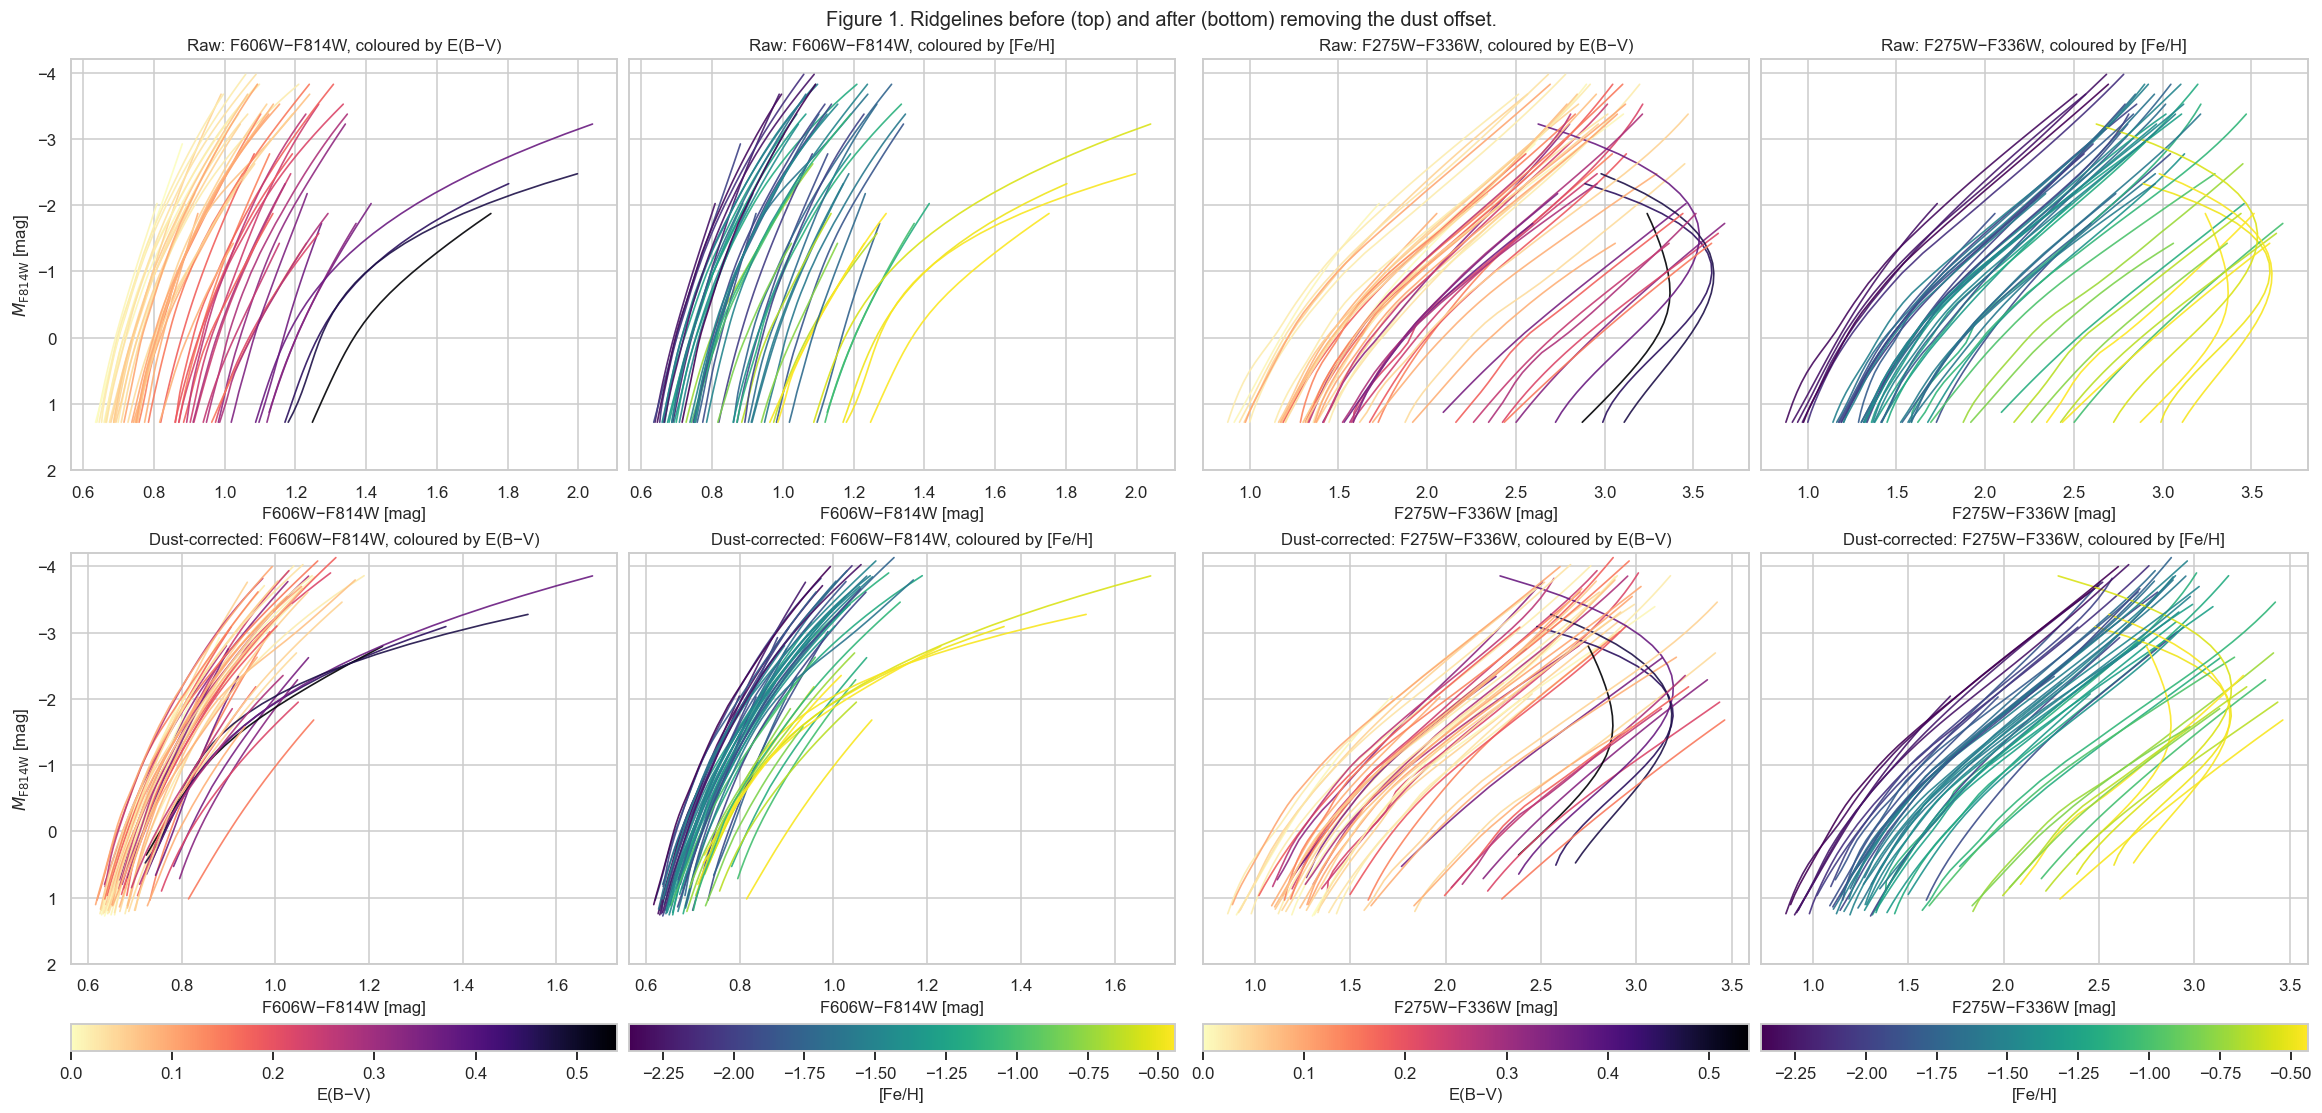

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(21, 10), constrained_layout=True, sharey=True)
nf, ne = plt.Normalize(fv.min(), fv.max()), plt.Normalize(ev.min(), ev.max())
for r, (R, tag) in enumerate([(raw, 'Raw'), (dd, 'Dust-corrected')]):
    for col, (c, vals, norm, cmap, lab) in enumerate([('F606W-F814W', ebv_all, ne, plt.cm.magma_r, 'E(B' + MINUS + 'V)'),
                                                      ('F606W-F814W', labels, nf, plt.cm.viridis, '[Fe/H]'),
                                                      ('F275W-F336W', ebv_all, ne, plt.cm.magma_r, 'E(B' + MINUS + 'V)'),
                                                      ('F275W-F336W', labels, nf, plt.cm.viridis, '[Fe/H]')]):
        ax = axes[r, col]
        for n in common:
            d = R[n]; ax.plot(d[c], d['F814W_abs'], color=cmap(norm(vals[n])), lw=1.1, alpha=0.9)
        ax.set_ylim(2.0, -4.2); ax.set_xlabel(nice(c) + ' [mag]')
        ax.set_title(f'{tag}: {nice(c)}, coloured by {lab}')
        if col == 0: ax.set_ylabel(MLAB)
        if r == 1: fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, label=lab, orientation='horizontal', pad=0.02)
fig.suptitle('Figure 1. Ridgelines before (top) and after (bottom) removing the dust offset.', fontsize=13)
plt.show()

**In plain words (Figure 1).** Each line is one cluster's red-giant track. *Top row, raw:* the lines fan out, and the dustiest clusters (dark in the E(B−V) panels) sit far to the red. *Bottom row, corrected:* the fan collapses into a much tighter band, and in the optical colour (left pair) the remaining spread lines up with **metallicity** (the viridis panels) rather than dust. In the ultraviolet colour (right pair) a faint dust gradient is still visible, since the darkest lines still sit slightly to the red. So the correction removes most of the dust effect, not all of it.

## 2. Is any dust signal left in the colours?

For each colour we ask: *at fixed metallicity, does the ridge still shift with E(B−V)?* If the correction is right, the answer should be no. (Method: a straight-line fit of the colour at M = 0 against [Fe/H] and E(B−V), fitted across clusters.)

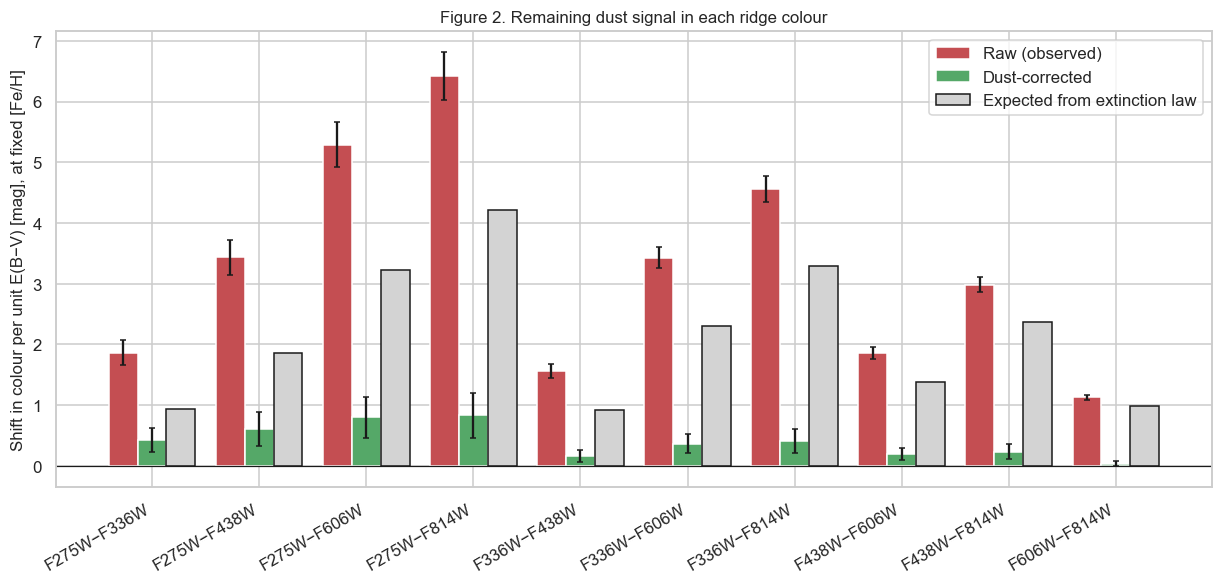

,raw slope,corrected slope,law,% removed
F275W−F336W,1.86,0.42,0.93,77.29
F275W−F438W,3.43,0.60,1.85,82.47
F275W−F606W,5.29,0.80,3.23,84.92
F275W−F814W,6.42,0.83,4.22,87.00
F336W−F438W,1.56,0.16,0.92,89.57
F336W−F606W,3.43,0.36,2.31,89.46
F336W−F814W,4.56,0.41,3.30,91.08
F438W−F606W,1.86,0.20,1.38,89.29
F438W−F814W,2.99,0.23,2.37,92.20
F606W−F814W,1.13,0.04,0.99,96.75


In [7]:
fig, ax = plt.subplots(figsize=(11, 5.2), constrained_layout=True)
x = np.arange(ncol); w = 0.27
ax.bar(x - w, slopes[RAWN][:, 0], w, yerr=slopes[RAWN][:, 1], label='Raw (observed)', color='C3', capsize=2)
ax.bar(x, slopes[DDN][:, 0], w, yerr=slopes[DDN][:, 1], label='Dust-corrected', color='C2', capsize=2)
ax.bar(x + w, law_slope, w, label='Expected from extinction law', color='lightgray', edgecolor='k')
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(x); ax.set_xticklabels([nice(c) for c in COLORS], rotation=30, ha='right')
ax.set_ylabel('Shift in colour per unit E(B' + MINUS + 'V) [mag], at fixed [Fe/H]')
ax.legend(); ax.set_title('Figure 2. Remaining dust signal in each ridge colour')
plt.show()
rem = pd.DataFrame({'raw slope': slopes[RAWN][:, 0], 'corrected slope': slopes[DDN][:, 0], 'law': law_slope}, index=[nice(c) for c in COLORS])
rem['% removed'] = (1 - rem['corrected slope'] / rem['raw slope']) * 100
display(rem.round(2))

**In plain words (Figure 2).** The red bars are the dust effect in the raw data: large, and bigger for colours that span more of the spectrum. The grey bars are what the extinction law says it should be. The green bars, after the correction, are far smaller (the table gives the numbers, 77 to 97% removed in this run): the optical colour F606W−F814W drops to essentially zero. But the ultraviolet colours keep a small positive residual, so the correction is good but **not perfect**. Two caveats on reading this plot: (i) the raw bars are larger than the grey law bars partly because the correction also shifts the *magnitude* axis, which moves a ridge along itself, and partly because dust and metallicity are tangled in this sample; (ii) possible causes of the residual are an imperfect catalogue E(B−V), a slightly different R_V, the temperature dependence of extinction, or the nonlinear metallicity dependence of UV colours.

## 3. The key comparison: does adding E(B−V) still help?

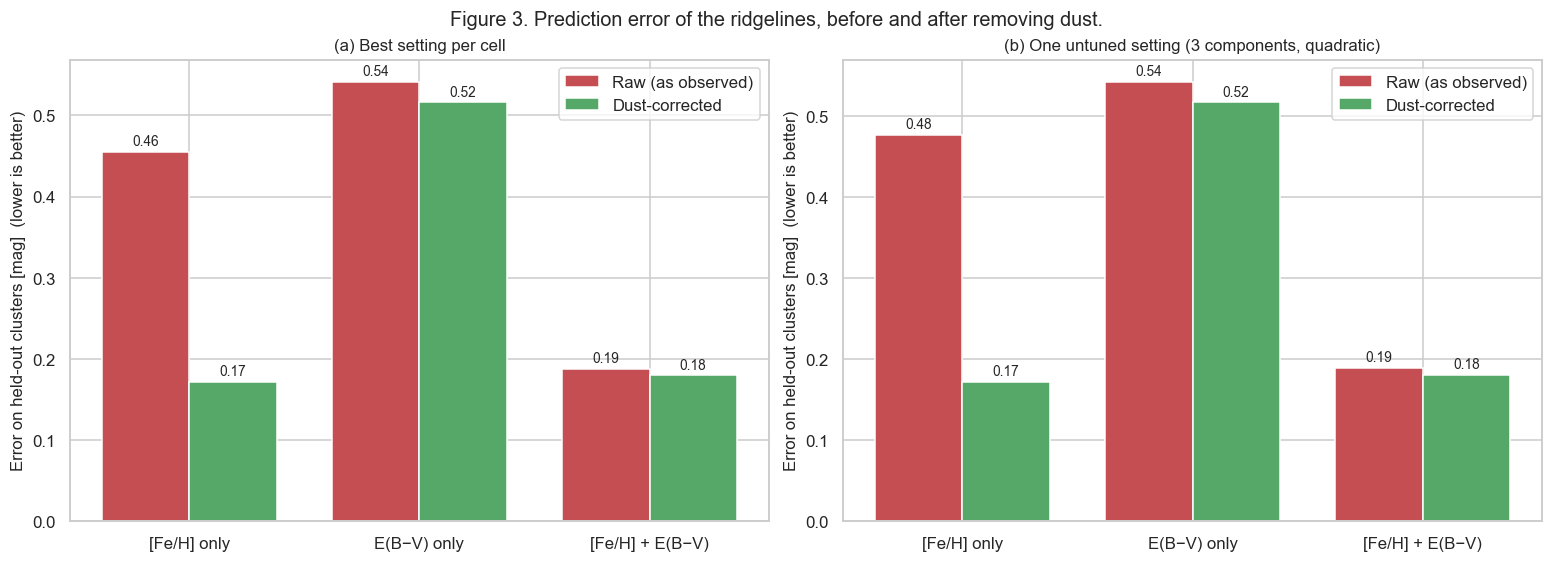

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
order = [FE, 'E(B' + MINUS + 'V) only', FEE]
for ax, key, title in [(axes[0], 'best', '(a) Best setting per cell'), (axes[1], 'fixed', '(b) One untuned setting (3 components, quadratic)')]:
    x = np.arange(len(order)); w = 0.38
    for j, (dname, col) in enumerate(zip(DATASETS, ['C3', 'C2'])):
        vals = [scen[(dname, i)]['best']['rmse'] if key == 'best' else scen[(dname, i)]['fixed_rmse'] for i in order]
        bars = ax.bar(x + (j - 0.5) * w, vals, w, label=dname, color=col)
        for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 0.008, f'{v:.2f}', ha='center', fontsize=9)
    ax.set_xticks(x); ax.set_xticklabels(order)
    ax.set_ylabel('Error on held-out clusters [mag]  (lower is better)'); ax.set_title(title); ax.legend()
fig.suptitle('Figure 3. Prediction error of the ridgelines, before and after removing dust.', fontsize=13)
plt.show()

**In plain words (Figure 3).** Lower bars are better. *Red (raw data):* knowing only metallicity leaves a large error; knowing metallicity **and** dust cuts it by more than half. *Green (dust-corrected):* metallicity alone already gives the small error, and adding dust information changes nothing. The "dust" information was only needed because the data hadn't been corrected for it. Panel (b) uses one fixed model setting, so the conclusion doesn't depend on tuning.

*Technical note.* Dust-only models (middle bars) stay poor in both versions. Correcting the data does not make E(B−V) a useful predictor of the ridge. It just removes the confound with [Fe/H].

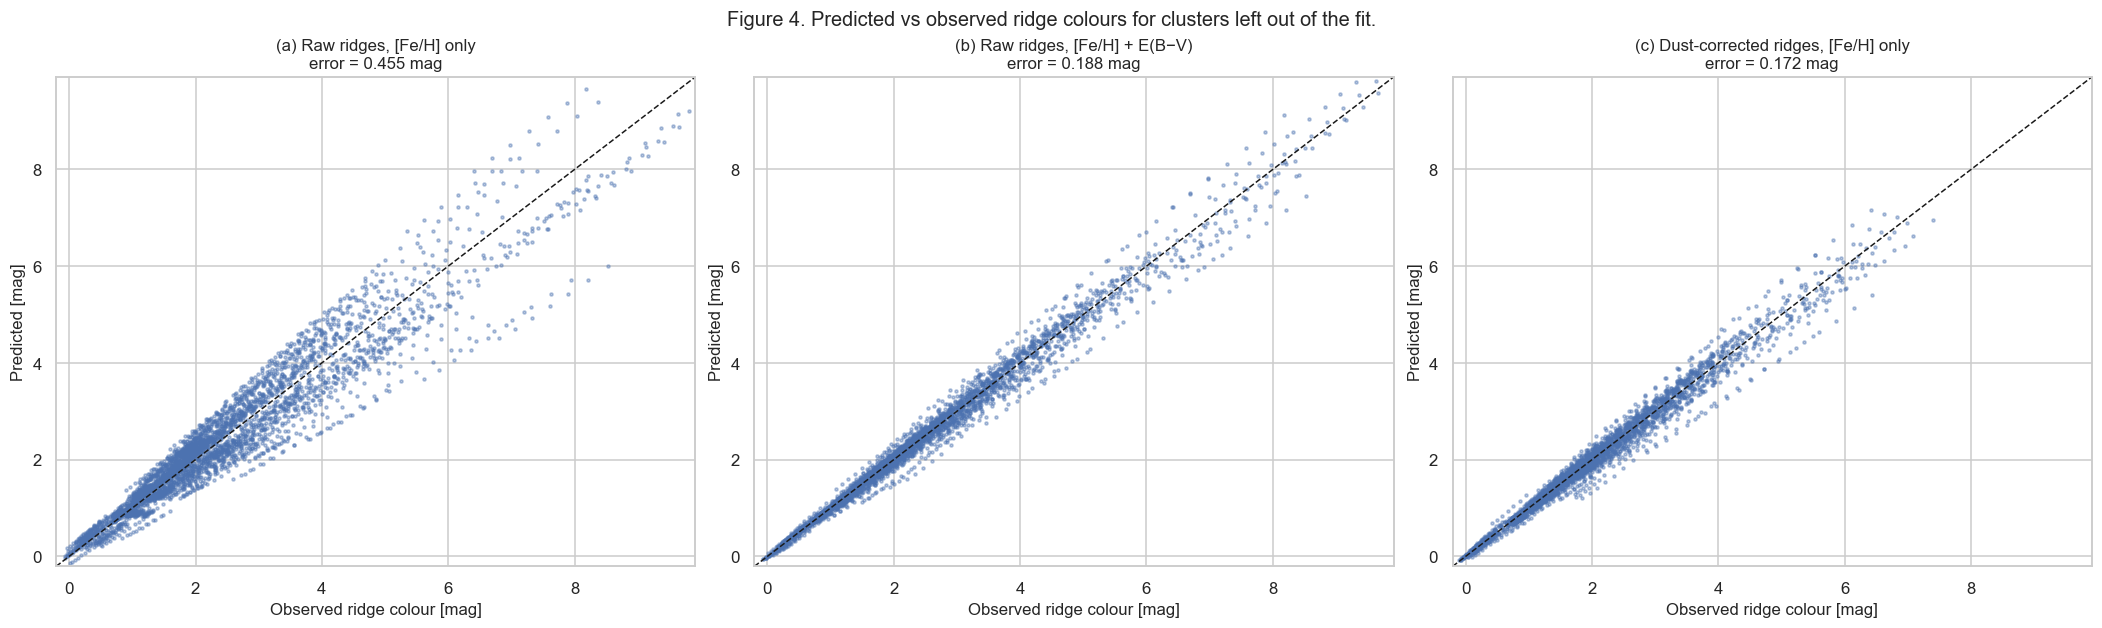

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.6), constrained_layout=True)
lim = [min(Yraw.min(), Ydd.min()) - .1, max(Yraw.max(), Ydd.max()) + .1]
for ax, (dname, iname), t in zip(axes, [(RAWN, FE), (RAWN, FEE), (DDN, FE)],
                                 ['(a) Raw ridges, [Fe/H] only', '(b) Raw ridges, [Fe/H] + E(B' + MINUS + 'V)', '(c) Dust-corrected ridges, [Fe/H] only']):
    Y = DATASETS[dname]; P = scen[(dname, iname)]['best']['P']
    ax.scatter(Y.ravel(), P.ravel(), s=4, alpha=0.4)
    ax.plot(lim, lim, 'k--', lw=1); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('Observed ridge colour [mag]'); ax.set_ylabel('Predicted [mag]')
    ax.set_title(f'{t}\nerror = {rmse(P, Y):.3f} mag')
fig.suptitle('Figure 4. Predicted vs observed ridge colours for clusters left out of the fit.', fontsize=13)
plt.show()

**In plain words (Figure 4).** Every dot is one colour at one brightness for one cluster, predicted by a model that never saw that cluster. A perfect model puts all dots on the dashed line. (a) Metallicity only, raw data: wide scatter. (b) Adding dust: tight. (c) Metallicity only, **after** the dust correction: just as tight, without needing the dust value.

## 4. Is the correction the right size?

If our correction were too weak, dust would remain; if too strong, we would over-correct and create a new offset in the opposite direction. We scale the extinction by a factor *s* (s = 0 means no correction, s = 1 is the physical value) and see which value gives the smallest [Fe/H]-only error.

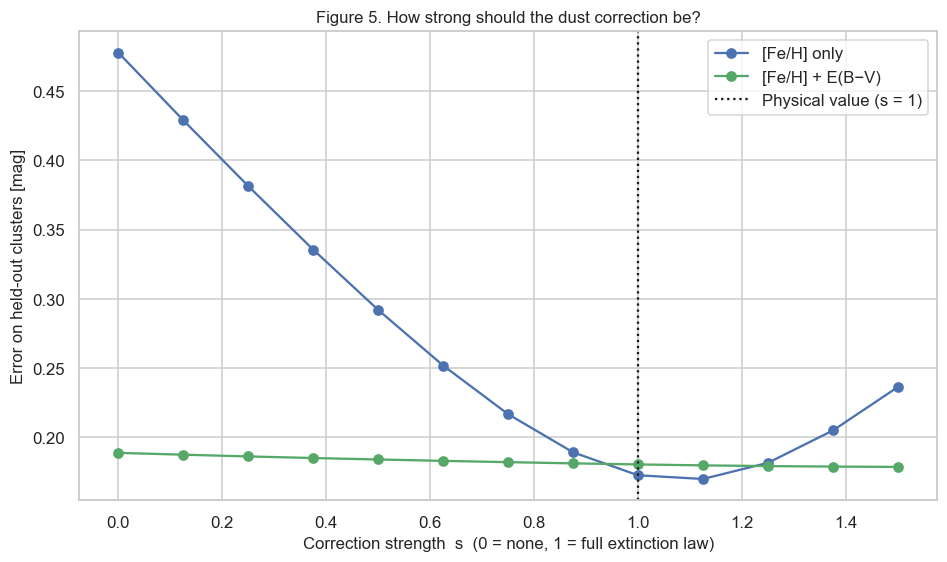

[Fe/H]-only error is lowest at **s = 1.125** (0.170 mag); at s = 0 it is 0.478 and at s = 1 it is 0.173 mag. (Fixed model, three magnitude bins, so numbers differ slightly from Figure 3.)

In [10]:
fig, ax = plt.subplots(figsize=(8.5, 5), constrained_layout=True)
for (name, vals), c in zip(sweep.items(), ['C0', 'C2']):
    ax.plot(S_VALUES, vals, marker='o', color=c, label=name)
ax.axvline(1, color='k', ls=':', label='Physical value (s = 1)')
best_s = S_VALUES[int(np.argmin(sweep['[Fe/H] only']))]
ax.set_xlabel('Correction strength  s  (0 = none, 1 = full extinction law)'); ax.set_ylabel('Error on held-out clusters [mag]')
ax.set_title('Figure 5. How strong should the dust correction be?'); ax.legend()
plt.show()
display(Markdown(f'[Fe/H]-only error is lowest at **s = {best_s}** ({min(sweep[FE]):.3f} mag); at s = 0 it is {sweep[FE][0]:.3f} and at s = 1 it is {sweep[FE][int(np.where(S_VALUES == 1)[0][0])]:.3f} mag. (Fixed model, three magnitude bins, so numbers differ slightly from Figure 3.)'))

**In plain words (Figure 5).** With no correction (left) the metallicity-only model is bad. Turning the correction up, the error drops fast and bottoms out near the physical value, then rises again if we overdo it. A minimum near s = 1 means the standard extinction law, with the catalogue E(B−V), is about the right size for this data (the exact minimum is printed above; a value slightly above 1 would fit the small UV residual in Figure 2). The blue line (metallicity only) approaches the green line (metallicity + dust) as the dust is removed.

## 5. Where does the improvement show up?

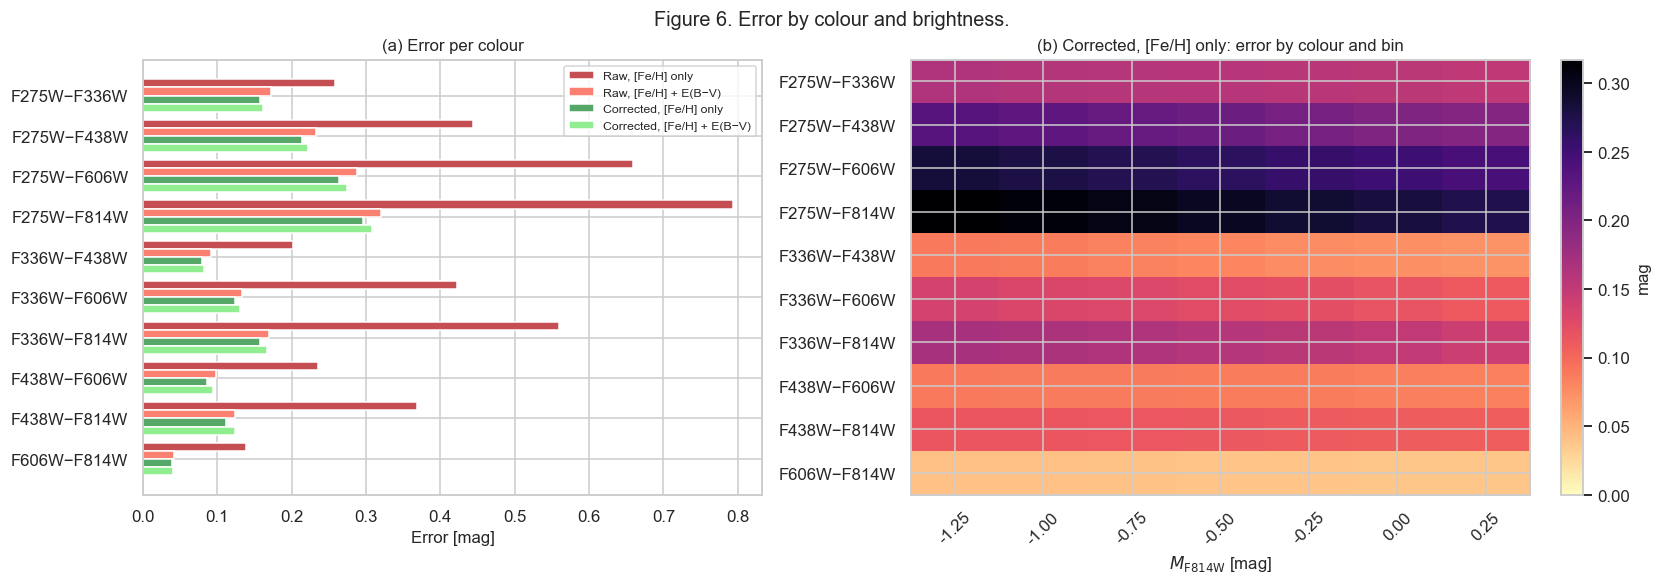

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2), constrained_layout=True)
yy = np.arange(ncol)
series = [(RAWN, FE, 'Raw, [Fe/H] only', 'C3', 0.0), (RAWN, FEE, 'Raw, [Fe/H] + E(B' + MINUS + 'V)', 'salmon', 0.2),
          (DDN, FE, 'Corrected, [Fe/H] only', 'C2', 0.4), (DDN, FEE, 'Corrected, [Fe/H] + E(B' + MINUS + 'V)', 'lightgreen', 0.6)]
for dname, iname, lab, c, off in series:
    Y = DATASETS[dname]; P = scen[(dname, iname)]['best']['P']
    per = np.sqrt(((P - Y) ** 2).mean(0)).reshape(ncol, nbin).mean(1)
    axes[0].barh(yy + off - 0.3, per, 0.2, label=lab, color=c)
axes[0].set_yticks(yy); axes[0].set_yticklabels([nice(c) for c in COLORS]); axes[0].invert_yaxis()
axes[0].set_xlabel('Error [mag]'); axes[0].legend(fontsize=8); axes[0].set_title('(a) Error per colour')
Ysd = DATASETS[DDN]; Pfe = scen[(DDN, FE)]['best']['P']
im = axes[1].imshow(np.sqrt(((Pfe - Ysd) ** 2).mean(0)).reshape(ncol, nbin), aspect='auto', cmap='magma_r', vmin=0)
axes[1].set_xticks(range(nbin)); axes[1].set_xticklabels([f'{g:.2f}' for g in GRID], rotation=45)
axes[1].set_yticks(range(ncol)); axes[1].set_yticklabels([nice(c) for c in COLORS]); axes[1].set_xlabel(MLAB)
axes[1].set_title('(b) Corrected, [Fe/H] only: error by colour and bin'); fig.colorbar(im, ax=axes[1], label='mag')
fig.suptitle('Figure 6. Error by colour and brightness.', fontsize=13)
plt.show()

**In plain words (Figure 6).** Panel (a): the red bars (raw data, metallicity only) are tall, especially for ultraviolet colours that dust affects most. Everything else, including the corrected data with metallicity only (dark green), is much lower. Panel (b): after correction, the remaining error is fairly even across brightness, with no obvious weak spot.

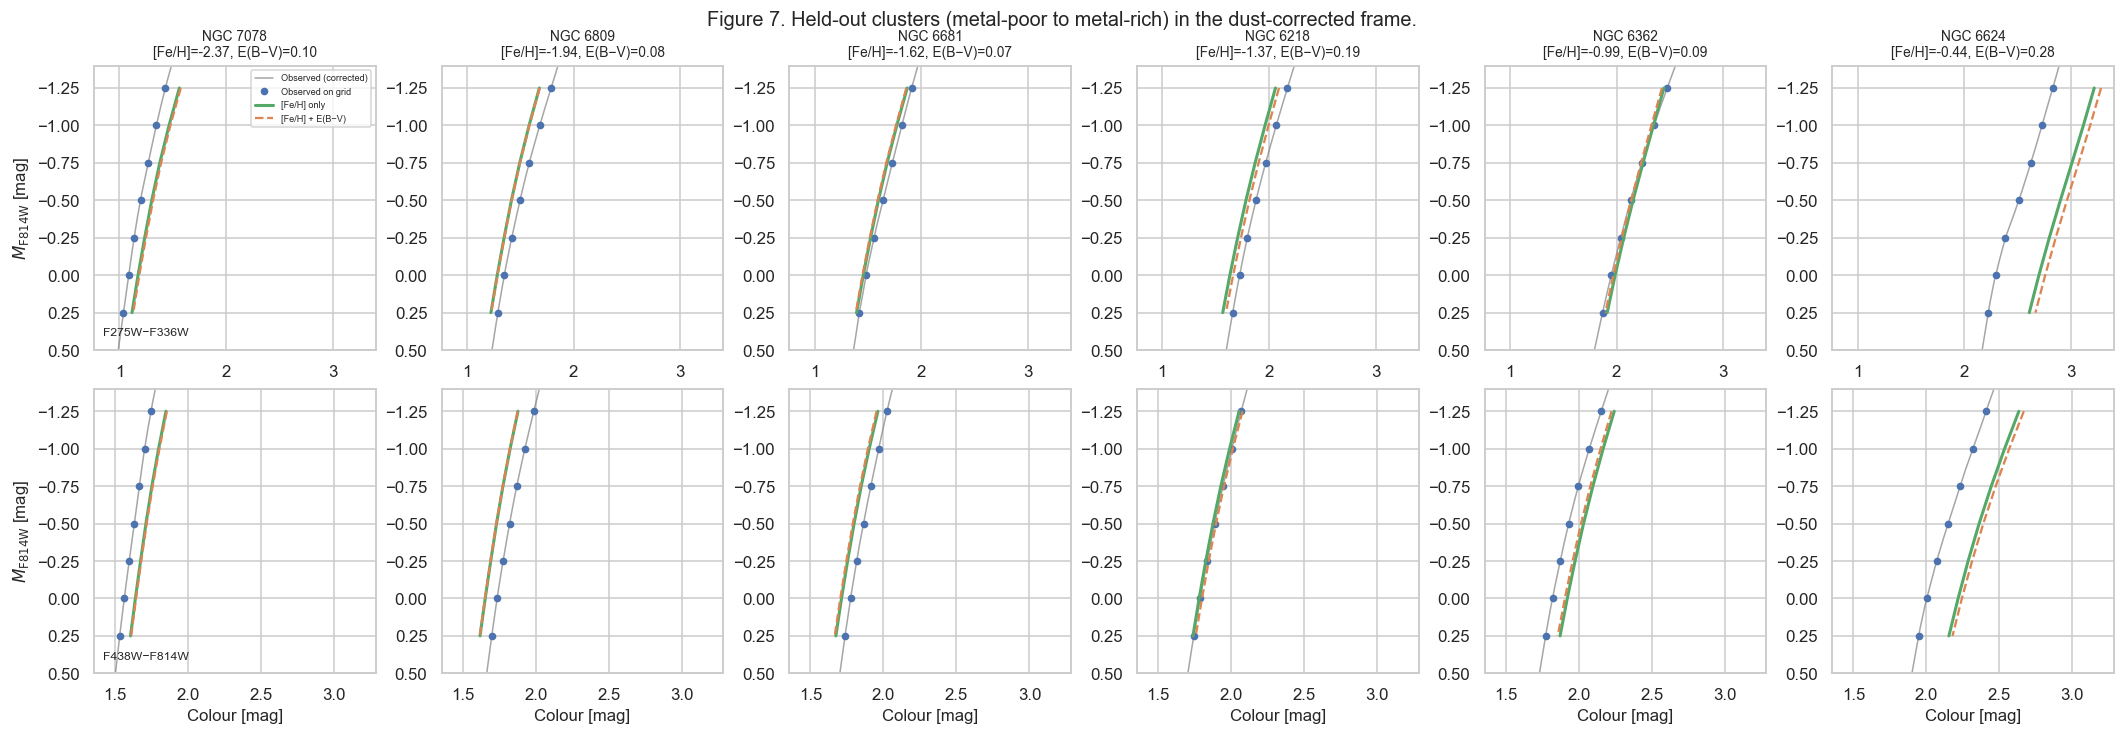

In [12]:
order_f = np.argsort(fv); pick = order_f[np.linspace(0, len(order_f) - 1, 6).astype(int)]
show = ['F275W-F336W', 'F438W-F814W']
Pe = scen[(DDN, FEE)]['best']['P']
fig, axes = plt.subplots(len(show), len(pick), figsize=(3.2 * len(pick), 3.2 * len(show)), sharex='row', constrained_layout=True)
for j, i in enumerate(pick):
    n = common[i]
    for r, c in enumerate(show):
        ci = COLORS.index(c); sl = slice(ci * nbin, (ci + 1) * nbin); ax = axes[r, j]
        ax.plot(dd[n][c], dd[n]['F814W_abs'], color='gray', lw=1, alpha=0.7, label='Observed (corrected)')
        ax.plot(Ydd[i, sl], GRID, 'o', color='C0', ms=4, label='Observed on grid')
        ax.plot(Pfe[i, sl], GRID, '-', color='C2', lw=2, label='[Fe/H] only')
        ax.plot(Pe[i, sl], GRID, '--', color='C1', lw=1.5, label='[Fe/H] + E(B' + MINUS + 'V)')
        ax.set_ylim(0.5, -1.4)
        if r == 0: ax.set_title(f'NGC {n}\n[Fe/H]={fv[i]:.2f}, E(B' + MINUS + f'V)={ev[i]:.2f}', fontsize=9)
        if j == 0: ax.set_ylabel(MLAB); ax.text(0.03, 0.05, nice(c), transform=ax.transAxes, fontsize=8)
        if r == len(show) - 1: ax.set_xlabel('Colour [mag]')
axes[0, 0].legend(fontsize=6)
fig.suptitle('Figure 7. Held-out clusters (metal-poor to metal-rich) in the dust-corrected frame.', fontsize=13, y=1.02)
plt.show()

**In plain words (Figure 7).** Each column is a cluster the model never saw. The solid green line (metallicity only) and the dashed orange line (metallicity + dust) lie on top of each other and both follow the observed track. After correction, telling the model about the dust adds nothing, because the dust is already gone from the data.

## 6. Going the other way: estimating [Fe/H] from the ridgeline

We also compare how well a cluster's metallicity can be read off its ridgeline, with and without the correction. (Direct regression; "with E(B−V)" means we also give the model the dust value.)

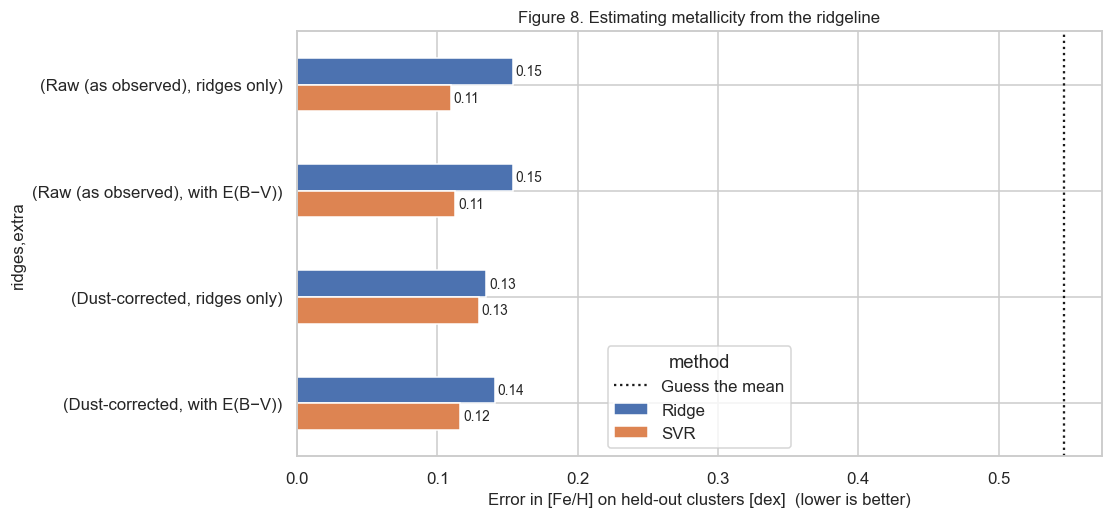

method                         Ridge    SVR
ridges            extra                    
Raw (as observed) ridges only  0.154  0.109
                  with E(B−V)  0.154  0.112
Dust-corrected    ridges only  0.135  0.129
                  with E(B−V)  0.141  0.116

In [13]:
rows = [dict(ridges=k[0], extra=k[1], method=k[2], RMSE=v['rmse']) for k, v in rev.items()]
rv = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(10, 4.6), constrained_layout=True)
piv = rv.pivot_table(index=['ridges', 'extra'], columns='method', values='RMSE').loc[
    [(RAWN, 'ridges only'), (RAWN, 'with E(B' + MINUS + 'V)'), (DDN, 'ridges only'), (DDN, 'with E(B' + MINUS + 'V)')]]
piv.plot.barh(ax=ax, color=['C0', 'C1'])
ax.axvline(fv.std(), color='k', ls=':', label='Guess the mean'); ax.invert_yaxis()
for cont in ax.containers: ax.bar_label(cont, fmt='%.2f', padding=2, fontsize=9)
ax.set_xlabel('Error in [Fe/H] on held-out clusters [dex]  (lower is better)'); ax.legend(title='method')
ax.set_title('Figure 8. Estimating metallicity from the ridgeline')
plt.show()
piv.round(3)

**In plain words (Figure 8).** The picture is mixed: the linear ridge model improves a little with the correction, the SVR gets slightly worse, and giving the models E(B−V) changes little. A flexible model like SVR can already learn to separate dust from metallicity by itself, so the correction matters less in this direction. The differences are small compared with the uncertainty of the catalogue metallicities (about 0.1 dex), so we do not read a trend into them.

## 7. Conclusions and caveats

**What we can say**
1. The HUGS ridgelines we were given behave like **uncorrected observed colours**: their cluster-to-cluster shifts track E(B−V) with the pattern the extinction law predicts.
2. Removing the dust offset with a standard extinction law makes [Fe/H] alone sufficient to explain the ridgelines, to within the precision of this test. The extra benefit of E(B−V) disappears (Figure 3). A small dust residual remains in the UV colours (Figure 2), too small to show up as a gain from E(B−V) with 53 clusters.
3. The correction strength that works best is close to the physical value (Figure 5), and a second extinction law (Gordon 2023) gives the same conclusion.
4. The new dust-corrected files are in `data/GC Ridgelines dereddened.zip` (and a Gordon-2023 variant). Use these when comparing ridgelines to stellar models or when predicting metallicity.

**Caveats**
* **Catalogue E(B−V).** One number per cluster from the Harris (2010) catalogue, with about 0.02 mag uncertainty. Differential reddening across a cluster is not modelled. R_V is fixed at 3.1, but bulge clusters are often closer to 2.5.
* **Stellar temperature.** We used a red-giant spectrum averaged between 4500 and 5000 K. Real stars span roughly 4000 to 5500 K along the giant branch, which shifts the extinction by up to ~0.1 in the F275W−F814W colour per unit E(B−V). A temperature-dependent correction would be a refinement.
* **Magnitude axis.** The correction also shifts each cluster brighter by its extinction, so the common magnitude range gets narrower (the dusty cluster NGC 6304 limits it here).
* **Small sample and selection.** 53 clusters. The model settings were picked from a small grid on the same data, which is why we also show one untuned setting. Treat differences of ~0.02 mag as ties.
* **Not yet verified:** that the HUGS team did not apply some partial correction we are unaware of. Please confirm with whoever produced the ridgelines.

**Next steps**
1. Replace the catalogue E(B−V) with a free parameter fitted per cluster and compare with Harris.
2. Make the correction temperature-dependent along the giant branch.
3. Compare the dust-corrected ridgelines with theoretical isochrones (MIST, Dartmouth).